# Project 9: Image Compression with SVD

## Introduction

The goal of this project is to understand and apply Singular Value Decomposition (SVD) for image compression.

SVD is a matrix factorization technique that decomposes a matrix into three matrices: U, S, and V^T. By keeping only the largest singular values and their corresponding singular vectors, we can approximate the original matrix using fewer components.

In this project, we use a grayscale image from `skimage.data` and apply SVD to its pixel matrix. We reconstruct the image using different ranks (5, 20, and 50) to investigate how the number of retained components affects image quality and compression efficiency.

The main objectives are:

- Convert an image to grayscale and extract its pixel matrix.
- Compute the Singular Value Decomposition.
- Inspect and analyze the singular values.
- Reconstruct the image using different ranks.
- Compare reconstruction quality at different ranks.
- Calculate the compression ratio.
- Visualize and compare the results.

The overall goal is to understand the trade-off between image quality and compression efficiency when using SVD.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color

In [2]:
image = data.astronaut()

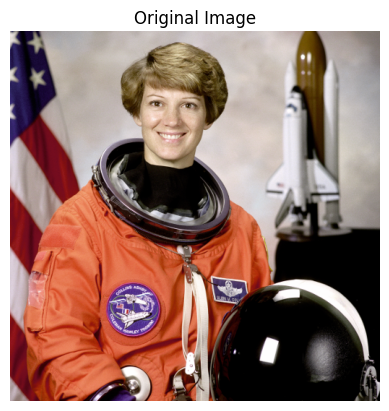

In [3]:
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [4]:
gray_image = color.rgb2gray(image)

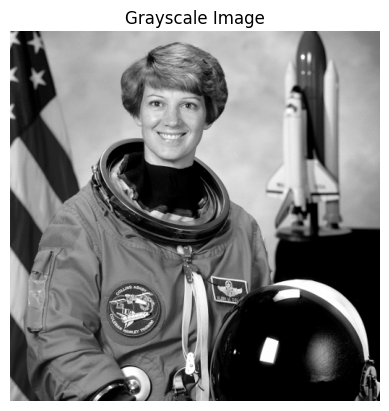

In [5]:
plt.imshow(gray_image, cmap='gray')
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

In [6]:
image_matrix = np.array(gray_image)
print("Image shape:", image_matrix.shape)
print("Data type:", image_matrix.dtype)
print("Minimum pixel value:", image_matrix.min())
print("Maximum pixel value:", image_matrix.max())

Image shape: (512, 512)
Data type: float64
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [7]:
#Compute Singular Value Decomposition (SVD)
U, S, Vt = np.linalg.svd(image_matrix, full_matrices=False)

print("U shape:", U.shape)
print("S shape:", S.shape)
print("Vt shape:", Vt.shape)

U shape: (512, 512)
S shape: (512,)
Vt shape: (512, 512)


In [8]:
#Inspect Singular Values
print('First 10 singular values:')
print(S[:10])

First 10 singular values:
[241.25751778  71.12185581  45.97712758  38.00791552  31.25038842
  29.98925186  28.45683894  21.94304069  21.85073754  18.91835586]


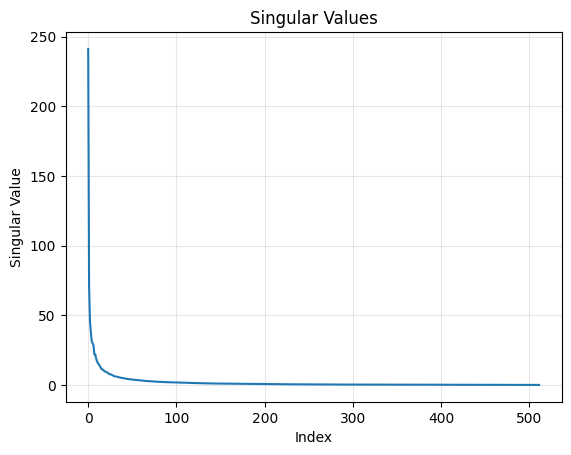

In [9]:
# Plot singular values
plt.plot(S)
plt.grid(alpha=0.3)
plt.title("Singular Values")
plt.xlabel("Index")
plt.ylabel("Singular Value")
plt.show()

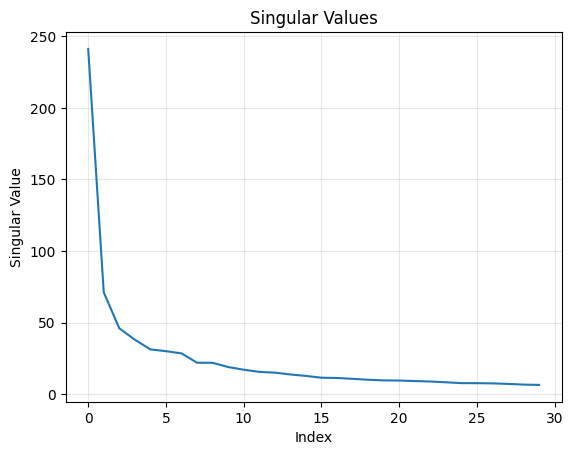

In [10]:
plt.plot(S[:30])
plt.grid(alpha=0.3)
plt.title("Singular Values")
plt.xlabel("Index")
plt.ylabel("Singular Value")
plt.show()

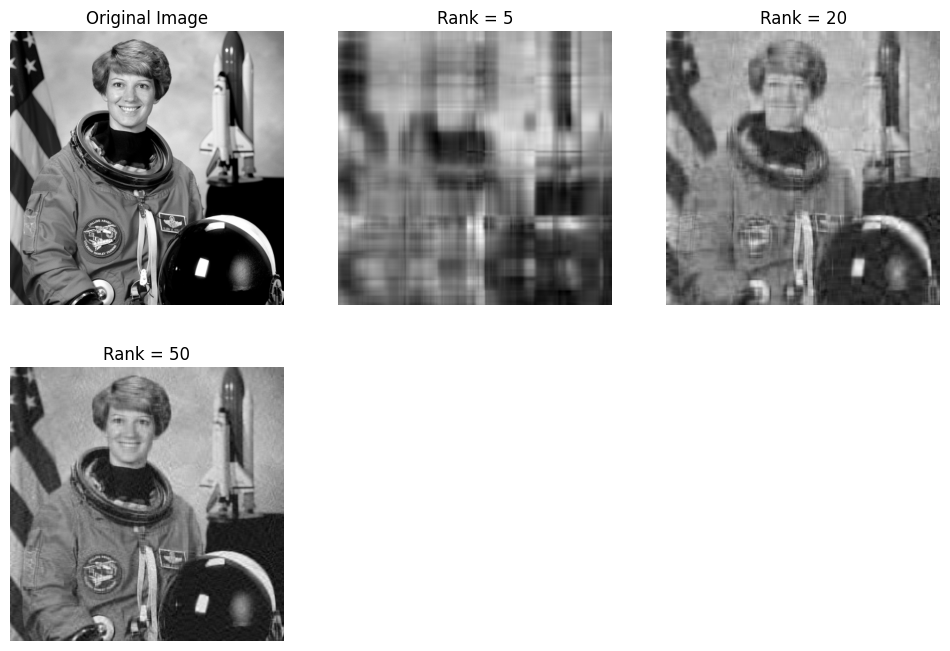

In [11]:
# Reconstruct the image using different ranks
rank = [512, 5, 20, 50]

plt.figure(figsize=(12, 8))

for i, k in enumerate(rank):
    reconstructed = (U[:, :k] * S[:k]) @ Vt[:k, :]

    plt.subplot(2, 3, i + 1)
    plt.imshow(reconstructed, cmap="gray")

    if k == 512:
        plt.title("Original Image")
    else:
        plt.title(f"Rank = {k}")

    plt.axis("off")

plt.show()

In [12]:
# Quantitative Reconstruction Quality
def calculate_metrics(original , reconstructed):
    mse = np.mean((original- reconstructed)**2)
    psnr = 10* np.log10(1/mse)

    return mse,psnr

In [13]:
mse_values = []
psnr_values = []
compression_ratios = []

#rank = [5, 20, 50]
rank = [1, 5, 10, 20, 50, 100, 200, 512]
for k in rank:
    reconstructed = (U[:, :k] * S[:k]) @ Vt[:k, :]
    mse, psnr = calculate_metrics(image_matrix, reconstructed)

    mse_values.append(mse)
    psnr_values.append(psnr)
    
    print(f"Rank {k:3d} | MSE: {mse:.6f} | PSNR: {psnr:.2f} dB")

Rank   1 | MSE: 0.060647 | PSNR: 12.17 dB
Rank   5 | MSE: 0.024051 | PSNR: 16.19 dB
Rank  10 | MSE: 0.012507 | PSNR: 19.03 dB
Rank  20 | MSE: 0.006135 | PSNR: 22.12 dB
Rank  50 | MSE: 0.001841 | PSNR: 27.35 dB
Rank 100 | MSE: 0.000515 | PSNR: 32.89 dB
Rank 200 | MSE: 0.000072 | PSNR: 41.42 dB
Rank 512 | MSE: 0.000000 | PSNR: 286.64 dB


In [14]:
# Compression Ratio
m , n = image_matrix.shape

for k in rank:
    original_size = m*n
    compressed_size = k*(m+n+1)

    compression_ratio = original_size / compressed_size
    compression_ratios.append(original_size / compressed_size)

    print(f'Rank {k}: {compression_ratio:.2f}:1')

Rank 1: 255.75:1
Rank 5: 51.15:1
Rank 10: 25.58:1
Rank 20: 12.79:1
Rank 50: 5.12:1
Rank 100: 2.56:1
Rank 200: 1.28:1
Rank 512: 0.50:1


In [15]:
mse_values
#psnr_values
#compression_ratios

[np.float64(0.060646512435135434),
 np.float64(0.02405058404175249),
 np.float64(0.012507299190328728),
 np.float64(0.006134912265482677),
 np.float64(0.0018409027540221353),
 np.float64(0.0005145521064032126),
 np.float64(7.207177342099768e-05),
 np.float64(2.165896104972374e-29)]

In [16]:
psnr_values

[np.float64(12.171941688077235),
 np.float64(16.188743728023937),
 np.float64(19.028364611595038),
 np.float64(22.12191643676862),
 np.float64(27.349691525644516),
 np.float64(32.885706396040696),
 np.float64(41.42234791420819),
 np.float64(286.643623797141)]

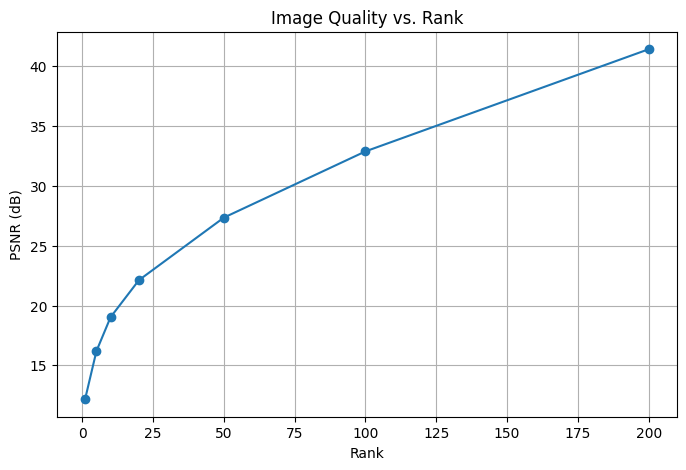

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(rank[:-1], psnr_values[:-1], marker='o')

plt.xlabel('Rank')
plt.ylabel('PSNR (dB)')
plt.title('Image Quality vs. Rank')
plt.grid(True)

plt.show()

In [18]:
compression_ratios

[255.75024390243902,
 51.15004878048781,
 25.575024390243904,
 12.787512195121952,
 5.11500487804878,
 2.55750243902439,
 1.278751219512195,
 0.4995121951219512]

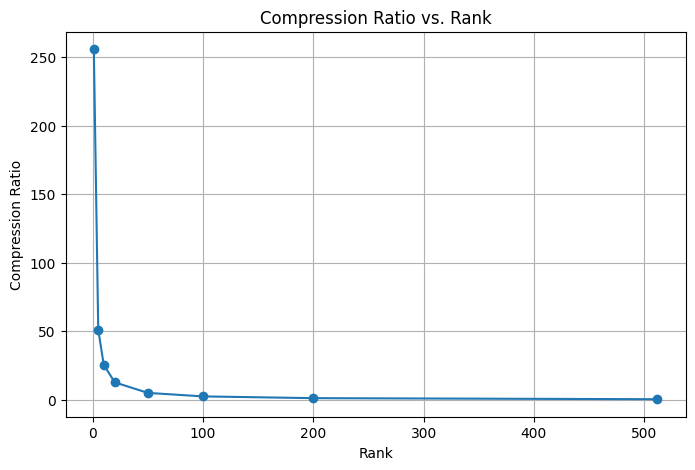

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(rank, compression_ratios, marker='o')

plt.xlabel('Rank')
plt.ylabel('Compression Ratio')
plt.title('Compression Ratio vs. Rank')
plt.grid(True)

plt.show()

## Conclusion

In this project, Singular Value Decomposition (SVD) was used to compress a grayscale image by approximating its pixel matrix with lower-rank representations.

The image was reconstructed using different numbers of singular values and corresponding singular vectors. The results demonstrated that increasing the rank improves reconstruction quality, as reflected by decreasing Mean Squared Error (MSE) and increasing Peak Signal-to-Noise Ratio (PSNR).

For example, Rank 5 achieved a compression ratio of 51.15:1 with a PSNR of 16.19 dB, while Rank 50 achieved a compression ratio of 5.12:1 with a PSNR of 27.35 dB. This illustrates the trade-off between compression efficiency and image quality.

Overall, SVD provides an effective mathematical approach to image compression by retaining the most significant components of an image while discarding less significant information. The choice of rank depends on the desired balance between storage efficiency and reconstruction quality.